# Mushroom Model Comparison & Error Analysis

## Contributors
- Pamela: model comparison, error analysis and conclusions
- Liam: Reviewed

This notebook compares the final mushroom models and looks more closely at the mistakes they make.

The project asks us to compare models using meaningful metrics, investigate poor or unexpected predictions, explain concrete errors and limitations, and iterate when the results suggest that we should.

For this problem, predicting a **poisonous mushroom as edible** is the most important error to watch.


## 1. Load the prepared data and recreate the same test split

The modelling notebook used a stratified 80/20 split with `random_state=42`.

We recreate exactly the same split here so the saved models are evaluated on the same test set.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

RANDOM_STATE = 42

df = pd.read_csv("mushroom_cleaned.csv")
X = df.drop(columns="class")
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Test rows:", len(X_test))
print(y_test.value_counts())


Test rows: 1000
class
e    621
p    379
Name: count, dtype: int64


## 2. Load the trained models

The Random Forest model was saved by PyCaret, while XGBoost was saved with `joblib`.

We load the already-trained models instead of training them again so this notebook stays focused on evaluation.


In [2]:
from pycaret.classification import load_model
from joblib import load

rf_model = load_model("random_forest_final")
xgb_model = load("xgboost_final.joblib")


Transformation Pipeline and Model Successfully Loaded


## 3. Generate predictions

For both models we keep the predicted class and the probability that a mushroom is poisonous.


In [3]:
from pycaret.classification import predict_model

# Random Forest
rf_output = predict_model(rf_model, data=X_test.copy())

rf_pred = rf_output["prediction_label"].to_numpy()
rf_prob_p = rf_model.predict_proba(X_test)[:, 1]

# XGBoost
xgb_pred_binary = xgb_model.predict(X_test)
xgb_pred = np.where(xgb_pred_binary == 1, "p", "e")
xgb_prob_p = xgb_model.predict_proba(X_test)[:, 1]


## 4. Compare the main metrics

Accuracy alone is not enough.

We compare:
- **Accuracy**
- **Balanced accuracy**
- **Poisonous precision**
- **Poisonous recall**
- **Poisonous F1**
- **ROC AUC**

For this use case, **poisonous recall is especially important**, because a false negative means a poisonous mushroom was predicted as edible.


In [4]:
def model_metrics(name, y_true, y_pred, prob_p):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "poisonous_precision": precision_score(y_true, y_pred, pos_label="p"),
        "poisonous_recall": recall_score(y_true, y_pred, pos_label="p"),
        "poisonous_f1": f1_score(y_true, y_pred, pos_label="p"),
        "roc_auc": roc_auc_score((y_true == "p").astype(int), prob_p),
    }

comparison = pd.DataFrame([
    model_metrics("Random Forest", y_test, rf_pred, rf_prob_p),
    model_metrics("XGBoost", y_test, xgb_pred, xgb_prob_p)
])

comparison.round(3)


,model,accuracy,balanced_accuracy,poisonous_precision,poisonous_recall,poisonous_f1,roc_auc
0,Random Forest,0.796,0.759,0.809,0.604,0.692,0.839
1,XGBoost,0.810,0.771,0.844,0.612,0.709,0.842


## 5. Confusion matrices

The confusion matrix shows the mistakes directly.

The most serious error is:

**actual poisonous → predicted edible**


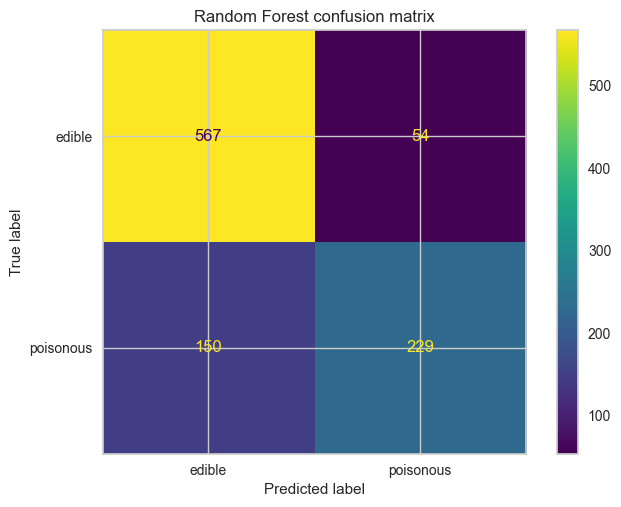

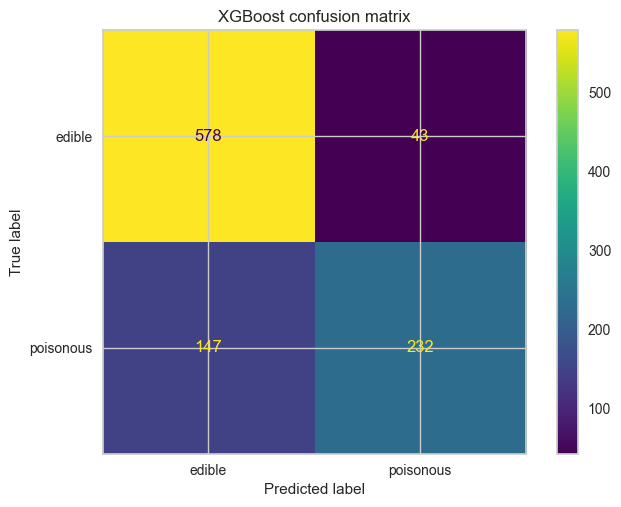

In [5]:
fig, ax = plt.subplots()
ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_pred, labels=["e", "p"]),
    display_labels=["edible", "poisonous"]
).plot(ax=ax)
ax.set_title("Random Forest confusion matrix")
plt.show()

fig, ax = plt.subplots()
ConfusionMatrixDisplay(
    confusion_matrix(y_test, xgb_pred, labels=["e", "p"]),
    display_labels=["edible", "poisonous"]
).plot(ax=ax)
ax.set_title("XGBoost confusion matrix")
plt.show()


## 6. Count the dangerous errors

Here we count the poisonous mushrooms that were predicted as edible.


In [6]:
rf_fn = (y_test == "p") & (rf_pred == "e")
xgb_fn = (y_test == "p") & (xgb_pred == "e")

dangerous_errors = pd.DataFrame({
    "model": ["Random Forest", "XGBoost"],
    "poisonous_predicted_edible": [rf_fn.sum(), xgb_fn.sum()],
    "total_poisonous_test": [(y_test == "p").sum(), (y_test == "p").sum()]
})

dangerous_errors["miss_rate"] = (
    dangerous_errors["poisonous_predicted_edible"]
    / dangerous_errors["total_poisonous_test"]
)

dangerous_errors.round(3)


,model,poisonous_predicted_edible,total_poisonous_test,miss_rate
0,Random Forest,150,379,0.396
1,XGBoost,147,379,0.388


### Why this matters

A model can have a decent overall accuracy while still making too many dangerous mistakes.

If many poisonous mushrooms are predicted as edible, the model is not safe enough for real-world mushroom identification.


## 7. Inspect XGBoost false negatives

Now we look at the poisonous mushrooms that XGBoost missed.

The goal is to check whether these mistakes have anything in common.


In [7]:
xgb_false_negatives = X_test.loc[xgb_fn].copy()
xgb_false_negatives["actual"] = "p"
xgb_false_negatives["predicted"] = "e"
xgb_false_negatives["prob_poisonous"] = xgb_prob_p[xgb_fn]

print("XGBoost false negatives:", len(xgb_false_negatives))
xgb_false_negatives.head()


XGBoost false negatives: 147


,cap-diameter,stem-height,stem-width,gill-color,habitat,season,ring-type,cap-shape,stem-surface,actual,predicted,prob_poisonous
3613,NaN,14.59,33.28,unknown,d,u,f,x,y,p,e,0.150911
864,2.97,7.91,4.07,unknown,d,unknown,unknown,f,unknown,p,e,0.458097
2148,8.08,8.32,12.29,unknown,unknown,unknown,f,f,i,p,e,0.269340
4984,13.45,5.03,26.19,n,d,a,unknown,x,unknown,p,e,0.484872
3093,4.90,7.05,5.30,n,d,unknown,f,f,unknown,p,e,0.283425


## 8. Categorical patterns in false negatives

We compare categorical values among missed poisonous mushrooms with all poisonous mushrooms in the test set.

A larger share among the errors may point to a weak spot in the model.


In [8]:
categorical_columns = X_test.select_dtypes(exclude="number").columns.tolist()
all_poisonous = X_test.loc[y_test == "p"]

for col in categorical_columns:
    error_share = xgb_false_negatives[col].value_counts(normalize=True).rename("false_negative_share")
    poisonous_share = all_poisonous[col].value_counts(normalize=True).rename("all_poisonous_share")

    check = pd.concat([error_share, poisonous_share], axis=1).fillna(0)
    check["difference"] = check["false_negative_share"] - check["all_poisonous_share"]

    print(f"\n--- {col} ---")
    display(check.sort_values("difference", ascending=False).head())



--- gill-color ---


,false_negative_share,all_poisonous_share,difference
gill-color,,,
w,0.278912,0.208443,0.070468
unknown,0.278912,0.242744,0.036168
p,0.122449,0.089710,0.032739
k,0.027211,0.015831,0.011380
b,0.013605,0.007916,0.005690



--- habitat ---


,false_negative_share,all_poisonous_share,difference
habitat,,,
l,0.068027,0.031662,0.036365
d,0.585034,0.554090,0.030944
u,0.006803,0.002639,0.004164
p,0.006803,0.007916,-0.001113
h,0.027211,0.034301,-0.007090



--- season ---


...

,false_negative_share,all_poisonous_share,difference
ring-type,,,
unknown,0.156463,0.129288,0.027175
f,0.727891,0.709763,0.018129
e,0.040816,0.034301,0.006516
r,0.027211,0.023747,0.003464
l,0.020408,0.018470,0.001939



--- cap-shape ---


,false_negative_share,all_poisonous_share,difference
cap-shape,,,
f,0.251701,0.179420,0.072281
s,0.129252,0.094987,0.034265
p,0.047619,0.034301,0.013318
x,0.421769,0.419525,0.002244
unknown,0.054422,0.063325,-0.008903



--- stem-surface ---


,false_negative_share,all_poisonous_share,difference
stem-surface,,,
unknown,0.721088,0.601583,0.119505
s,0.108844,0.079156,0.029688
k,0.027211,0.023747,0.003464
h,0.000000,0.013193,-0.013193
t,0.020408,0.036939,-0.016531


A positive `difference` means the value appears more often among the false negatives than among poisonous mushrooms in general.

This does not prove that the feature causes the mistake. It only shows a pattern worth checking.


## 9. Numerical patterns in false negatives


In [9]:
numeric_columns = X_test.select_dtypes(include="number").columns.tolist()

numeric_error_check = pd.DataFrame({
    "all_poisonous_mean": all_poisonous[numeric_columns].mean(),
    "false_negative_mean": xgb_false_negatives[numeric_columns].mean(),
    "all_poisonous_median": all_poisonous[numeric_columns].median(),
    "false_negative_median": xgb_false_negatives[numeric_columns].median(),
})

numeric_error_check


,all_poisonous_mean,false_negative_mean,all_poisonous_median,false_negative_median
cap-diameter,5.990000,6.278690,5.560,6.075
stem-height,6.320065,6.689123,5.695,5.885
stem-width,11.008386,12.780522,8.250,11.295


## 10. Where do Random Forest and XGBoost disagree?

This shows whether XGBoost is solving cases that Random Forest gets wrong, and whether it also introduces different mistakes.


In [10]:
disagreement = X_test.copy()
disagreement["actual"] = y_test
disagreement["rf_prediction"] = rf_pred
disagreement["xgb_prediction"] = xgb_pred

disagreement = disagreement[
    disagreement["rf_prediction"] != disagreement["xgb_prediction"]
]

rf_wrong_xgb_right = disagreement[
    (disagreement["rf_prediction"] != disagreement["actual"]) &
    (disagreement["xgb_prediction"] == disagreement["actual"])
]

xgb_wrong_rf_right = disagreement[
    (disagreement["xgb_prediction"] != disagreement["actual"]) &
    (disagreement["rf_prediction"] == disagreement["actual"])
]

print("Number of disagreements:", len(disagreement))
print("RF wrong, XGBoost right:", len(rf_wrong_xgb_right))
print("XGBoost wrong, RF right:", len(xgb_wrong_rf_right))


Number of disagreements: 90
RF wrong, XGBoost right: 52
XGBoost wrong, RF right: 38


## 11. ROC curves

ROC AUC compares how well both models separate edible and poisonous mushrooms across different thresholds.


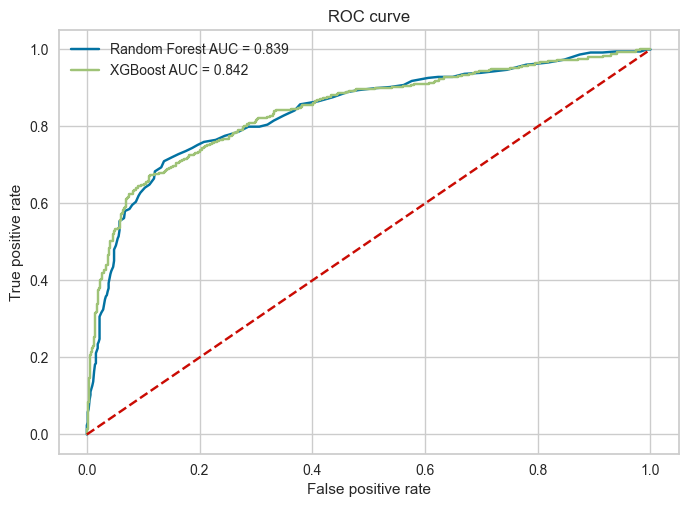

In [11]:
y_test_binary = (y_test == "p").astype(int)

rf_fpr, rf_tpr, _ = roc_curve(y_test_binary, rf_prob_p)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test_binary, xgb_prob_p)

plt.figure()
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest AUC = {roc_auc_score(y_test_binary, rf_prob_p):.3f}")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost AUC = {roc_auc_score(y_test_binary, xgb_prob_p):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()


### ROC interpretation

Both models have a ROC AUC of around 0.84, so they separate edible and poisonous mushrooms reasonably well.

XGBoost has a slightly higher AUC than Random Forest, but the difference is very small.

Because false negatives are especially important in this problem, we should not choose the final model based on ROC AUC alone. We also need to look at poisonous recall and the confusion matrix.

## 12. Iteration: test different XGBoost thresholds

The default threshold is 0.50.

Because missing a poisonous mushroom is more serious than incorrectly rejecting an edible mushroom, lowering the threshold may improve poisonous recall.

The trade-off is that more edible mushrooms may be predicted as poisonous.


In [12]:
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    pred = np.where(xgb_prob_p >= threshold, "p", "e")

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "poisonous_precision": precision_score(y_test, pred, pos_label="p"),
        "poisonous_recall": recall_score(y_test, pred, pos_label="p"),
        "poisonous_f1": f1_score(y_test, pred, pos_label="p"),
        "dangerous_errors": ((y_test == "p") & (pred == "e")).sum()
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)


,threshold,accuracy,balanced_accuracy,poisonous_precision,poisonous_recall,poisonous_f1,dangerous_errors
0,0.20,0.648,0.697,0.521,0.897,0.659,39
1,0.25,0.707,0.735,0.577,0.850,0.687,57
2,0.30,0.751,0.761,0.636,0.802,0.709,75
3,0.35,0.774,0.769,0.685,0.747,0.715,96
4,0.40,0.790,0.771,0.738,0.691,0.714,117
5,0.45,0.806,0.779,0.788,0.668,0.723,126
6,0.50,0.810,0.771,0.844,0.612,0.709,147
7,0.55,0.793,0.746,0.850,0.551,0.669,170
8,0.60,0.783,0.729,0.868,0.504,0.638,188
9,0.65,0.767,0.703,0.888,0.441,0.589,212


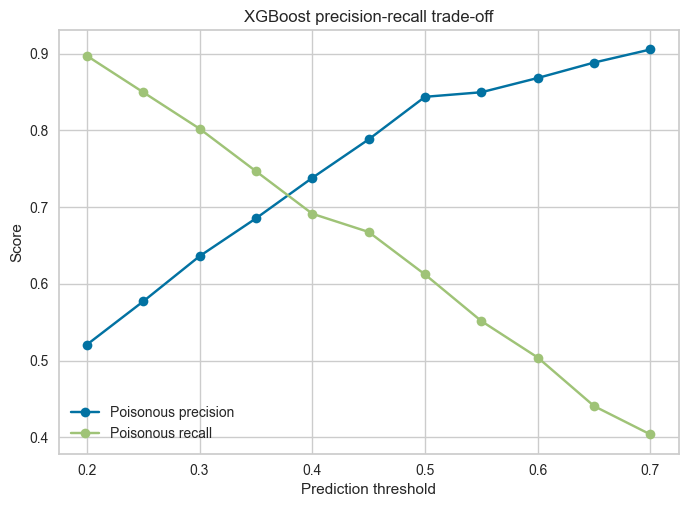

In [13]:
plt.figure()
plt.plot(threshold_df["threshold"], threshold_df["poisonous_precision"], marker="o", label="Poisonous precision")
plt.plot(threshold_df["threshold"], threshold_df["poisonous_recall"], marker="o", label="Poisonous recall")
plt.xlabel("Prediction threshold")
plt.ylabel("Score")
plt.title("XGBoost precision-recall trade-off")
plt.legend()
plt.show()


### Important note about the threshold experiment

We should not choose the final threshold only because it looks best on the final test set.

In a stricter workflow, threshold selection should happen using validation data or cross-validation, and the final test set should only be checked once afterwards.

Here, the experiment is mainly used to understand the trade-off and show how the model could be improved.


## 13.Conclusion

XGBoost performs slightly better than Random Forest on all of the main metrics.

Random Forest reached an accuracy of 0.796 and balanced accuracy of 0.759, while XGBoost reached 0.810 accuracy and 0.771 balanced accuracy.

The difference between the models is fairly small. This is also visible in the ROC AUC scores, which are 0.839 for Random Forest and 0.842 for XGBoost.

The most important weakness is poisonous recall. Random Forest missed 150 poisonous mushrooms, while XGBoost missed 147 out of 379 poisonous mushrooms in the test set. This means both models still classify roughly 4 out of 10 poisonous mushrooms as edible.

The false-negative analysis also shows some patterns. For example, missing `stem-surface` values and some cap shapes appear more often among the XGBoost false negatives than among poisonous mushrooms in general. These patterns do not prove that these features cause the errors, but they show where the model may struggle.

The two models disagreed on 90 mushrooms. In 52 of those cases XGBoost was correct while Random Forest was wrong, while Random Forest was correct in 38 cases where XGBoost was wrong. This supports XGBoost as the stronger model, but the advantage is not very large.

The threshold experiment shows that lowering the XGBoost decision threshold can improve poisonous recall and reduce dangerous false negatives, but this comes at the cost of lower precision and more edible mushrooms being classified as poisonous.

For deployment, XGBoost is the better candidate of the two because it performs slightly better overall. However, the current model should not be considered safe for real mushroom identification because poisonous recall is still too low.

## 14. Save the evaluation results


In [14]:
comparison.to_csv("mushroom_model_comparison.csv", index=False)
threshold_df.to_csv("xgboost_threshold_analysis.csv", index=False)

print("Saved mushroom_model_comparison.csv")
print("Saved xgboost_threshold_analysis.csv")


Saved mushroom_model_comparison.csv
Saved xgboost_threshold_analysis.csv
